# Домашнє завдання: ETL-пайплайни для аналітиків даних

Це ДЗ передбачене під виконання на локальній машині. Виконання з Google Colab буде суттєво ускладнене.

## Підготовка
1. Переконайтесь, що у вас встановлены необхідні бібліотеки:
   ```bash
   pip install sqlalchemy pymysql pandas matplotlib seaborn python-dotenv
   ```

2. Створіть файл `.env` з параметрами підключення до бази даних classicmodels. Базу даних ви можете отримати через

  - docker-контейнер згідно існтрукції в [документі](https://www.notion.so/hannapylieva/Docker-1eb94835849480c9b2e7f5dc22ee4df9), також відео інструкції присутні на платформі - уроки "MySQL бази, клієнт для роботи з БД, Docker і ChatGPT для запитів" та "Як встановити Docker для роботи з базами даних без терміналу"
  - або встановивши локально цю БД - для цього перегляньте урок "Опціонально. Встановлення MySQL та  БД Сlassicmodels локально".
  
  Приклад `.env` файлу ми створювали в лекції. Ось його обовʼязкове наповнення:
    ```
    DB_HOST=your_host
    DB_PORT=3306 або 3307 - той, який Ви налаштували
    DB_USER=your_username
    DB_PASSWORD=your_password
    DB_NAME=classicmodels
    ```
  Якщо ви створили цей файл під час перегляду лекції - **новий створювати не треба**. Замініть лише назву БД, або пропишіть назву в коді створення підключення (замість отримання назви цільової БД зі змінних оточення). Але переконайтесь, що до `.env` файл лежить в тій самій папці, що і цей ноутбук.

  **УВАГА!** НЕ копіюйте скрит для **створення** `.env` файлу. В лекції він наводиться для прикладу. І давалось пояснення, що в реальних проєктах ми НІКОЛИ не пишемо доступи до бази в коді. Копіювання скрипта для створення `.env` файлу сюди в ДЗ буде вважатись грубою помилкою і ми зніматимемо бали.

3. Налаштуйте підключення через SQLAlchemy до БД за прикладом в лекції.

Рекомендую вивести (відобразити) змінну engine після створення. Вона має бути не None! Якщо None - значить у Вас не підтягнулись налаштування з .env файла.

Ви також можете налаштувати параметри підключення до БД без .env файла, просто прописавши текстом в відповідних місцях. Це - не рекомендований підхід.

In [1]:
pip install sqlalchemy pymysql pandas matplotlib seaborn python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [12]:
import datetime
import requests
import json
import os

from dotenv import load_dotenv
import pandas as pd
import sqlalchemy as sa
from sqlalchemy import create_engine, text, MetaData, Table
from sqlalchemy.orm import sessionmaker

In [7]:
load_dotenv(override=True)

user = os.getenv('DB_USER')
password = os.getenv('DB_PASSWORD')
host = os.getenv('DB_HOST')
port = os.getenv('DB_PORT')

db = "classicmodels" 

connection_string = f"mysql+pymysql://{user}:{password}@{host}:{port}/{db}"
engine = create_engine(connection_string)

with engine.connect() as conn:
    current_db = conn.execute(text("SELECT DATABASE()")).scalar()
    print(f"✅ Зараз підключено до бази: {current_db}")

✅ Зараз підключено до бази: classicmodels


### Завдання 1: Створення таблиці курсів валют та API інтеграція (2 бали)

**Повторіть процедуру з лекції:** створіть таблицю для курсів валют, але вже в цій базі даних. Результатом має бути нова таблиця з курсами валют USD, EUR, UAH в БД (можна завантажити більше валют). Продемонструйте, що таблиця була додана, використовуючи SELECT.

Тобто тут ви можете прямо скопіювати код з лекції, внести необхідні зміни і запустити. Головне - отримати таблицю в БД classicmodels.

In [8]:
from datetime import datetime, date  # Імпортуємо обидва класи

def create_currency_table(engine):
    create_table_sql = text("""
    CREATE TABLE IF NOT EXISTS currency_rates (
        id INT AUTO_INCREMENT PRIMARY KEY,
        currency_code VARCHAR(3) NOT NULL,
        rate_to_usd DECIMAL(10, 6) NOT NULL,
        rate_date DATE NOT NULL,
        created_at TIMESTAMP DEFAULT CURRENT_TIMESTAMP,
        updated_at TIMESTAMP DEFAULT CURRENT_TIMESTAMP ON UPDATE CURRENT_TIMESTAMP,
        INDEX idx_currency_date (currency_code, rate_date),
        UNIQUE KEY unique_currency_date (currency_code, rate_date)
    )
    """)
    
    with engine.begin() as conn:
        conn.execute(create_table_sql)
    print("✅ Таблиця currency_rates готова до роботи")

def fetch_exchange_rates():
    
    try:
        url = "https://api.exchangerate-api.com/v4/latest/USD"
        response = requests.get(url, timeout=10)
        response.raise_for_status()
        data = response.json()

        target_currencies = ['UAH', 'EUR', 'GBP', 'CHF', 'CAD', 'AUD']
        rates = {cur: data['rates'][cur] for cur in target_currencies if cur in data['rates']}
        return rates, date.today()
        
    except Exception as e:
        print(f"❌ Помилка API: {e}")
        return None, None

def save_exchange_rates(engine, rates_dict, rate_date):
    if not rates_dict: return False

    insert_sql = text("""
    INSERT INTO currency_rates (currency_code, rate_to_usd, rate_date)
    VALUES (:currency, :rate, :date)
    ON DUPLICATE KEY UPDATE
        rate_to_usd = VALUES(rate_to_usd),
        updated_at = CURRENT_TIMESTAMP
    """)

    try:
        with engine.begin() as conn:
            for currency, rate in rates_dict.items():
                conn.execute(insert_sql, {
                    'currency': currency,
                    'rate': rate,
                    'date': rate_date
                })
        print(f"✅ Успішно синхронізовано {len(rates_dict)} курсів.")
        return True
        
    except Exception as e:
        print(f"❌ Помилка БД: {e}")
        return False

create_currency_table(engine)
rates, current_date = fetch_exchange_rates()

if rates:
    if save_exchange_rates(engine, rates, current_date):
        query = "SELECT currency_code, rate_to_usd, rate_date, updated_at FROM currency_rates ORDER BY rate_to_usd DESC"
        df_result = pd.read_sql(query, engine)
        
        print(f"\n📊 Актуальні курси валют на {current_date}:")
        display(df_result)


✅ Таблиця currency_rates готова до роботи
✅ Успішно синхронізовано 6 курсів.

📊 Актуальні курси валют на 2026-11-22:


,currency_code,rate_to_usd,rate_date,updated_at
0,UAH,45.000,2026-11-22,2026-11-22 12:05:12
1,AUD,1.510,2026-11-22,2026-11-22 12:05:12
2,CAD,1.430,2026-11-22,2026-11-22 12:05:12
3,EUR,0.911,2026-11-22,2026-11-22 12:05:12
4,CHF,0.840,2026-11-22,2026-11-22 12:05:12
5,GBP,0.764,2026-11-22,2026-11-22 12:05:12


# Завдання 2: Створення простого ETL пайплайну (7 балів)

В цьому завданні ми створимо повноцінний ETL процес для аналізу продажів ClassicModels.

Завдання обʼємне і оцінюється відповідно. Ви можете пропустити обчислення якихось з метрик, якщо відчуєте, що вже немає сил робити це завдання. Бал буде виставлено виходячи з виконаного обʼєму та його правильності.

## Що саме треба зробити:

### Extract (Витягування даних):
На цьому етапі треба витягнути дані з БД в pandas.DataFrame для подальшої обробки.
Які дані нам потрібні (кожен пункт - в окремий фрейм даних):
1. **дані про виконані замовлення за 2004 рік** - з'єднати таблиці orders, orderdetails, products, customers
2. **дані про продукти** - назви, категорії, ціни
3. **дані про курси валют** - використати дані з попереднього завдання

### Transform (Обробка даних):

#### 2.1 Додати розрахункові колонки до основної таблиці:
Додайте до DataFrame з продажами такі нові колонки:

- **`profit_per_item`** - прибуток з одного товару (використайте колонки: `priceEach` - `buyPrice`)
- **`total_profit`** - загальний прибуток з товарної позиції (використайте колонки: `profit_per_item` × `quantityOrdered`)
- **`total_amount_eur`** - сума в євро (використайте колонки: `total_amount` / `eur_rate`)

#### 2.2 Створити аналітичну таблицю по країнах (ТОП-5):
Згрупуйте дані по колонці **`country`** та обчисліть для кожної країни:

**Метрики для розрахунку:**
- **Кількість унікальних замовлень** - унікальні значення колонки `orderNumber`
- **Загальний дохід** - сума колонки `total_amount`
- **Загальний прибуток** - сума колонки `total_profit`
- **Кількість проданих товарів** - сума колонки `quantityOrdered`
- **Маржа прибутку (%)** - (`загальний прибуток` / `загальний дохід`) × 100

**Результат:** Таблиця з 5 найприбутковіших країн, відсортована за загальним доходом (від більшого до меншого).

#### 2.3 Створити аналітичну таблицю по продуктових лініях:
Згрупуйте дані по колонці **`productLine`** та обчисліть ті ж метрики:

**Метрики для розрахунку:**
- **Кількість унікальних замовлень** - унікальні значення колонки `orderNumber`
- **Загальний дохід** - сума колонки `total_amount`
- **Загальний прибуток** - сума колонки `total_profit`
- **Кількість проданих товарів** - сума колонки `quantityOrdered`
- **Маржа прибутку (%)** - (`загальний прибуток` / `загальний дохід`) × 100

**Результат:** Таблиця з усіма продуктовими лініями, відсортована за загальним доходом.

#### 2.4 Створити підсумкову інформацію (Executive Summary):
Розрахуйте загальні показники бізнесу за 2004 рік:

**Фінансові показники:**
- **Загальний дохід в доларах** - сума всієї колонки `total_amount`
- **Загальний дохід в євро** - сума всієї колонки `total_amount_eur`
- **Загальний прибуток в доларах** - сума всієї колонки `total_profit`
- **Загальна маржа прибутку (%)** - (`загальний прибуток` / `загальний дохід`) × 100
- **Середній розмір замовлення** - середнє значення колонки `total_amount`

**Операційні показники:**
- **Кількість унікальних замовлень** - унікальні значення колонки `orderNumber`
- **Кількість унікальних клієнтів** - унікальні значення колонки `customerName`
- **Період даних** - мінімальна та максимальна дата з колонки `orderDate`

**Топ показники:**
- **Найприбутковіша країна** - перший рядок з таблиці країн (колонка `country`)
- **Найприбутковіша продуктова лінія** - перший рядок з таблиці продуктів (колонка `productLine`)

### Load (Збереження результатів):
В цій частині ми зберігаємо результати наших обчислень.
Використайте приклади коду з лекцій та адаптуйте його під цей ETL процес.
Що Вам потрібно створити:

#### 3.1 Excel файл з трьома вкладками:
- **"Summary"** - підсумкова інформація у вигляді таблиці "Показник - Значення"
- **"Top_Countries"** - аналітика по топ-5 країнах
- **"Product_Lines"** - аналітика по всіх продуктових лініях

#### 3.2 Візуалізація:
- Створіть стовпчикову діаграму топ-5 країн за доходом.
- Створіть pie chart з відсотковим розподілом доходу в USD по продуктових лінійках.

## РЕКОМЕНДАЦІЇ ДО ВИКОНАННЯ:

### Покрокова стратегія виконання:
1. Спочатку протестуйте Extract просто в Jupyter notebook (без фукнції) - переконайтеся що SQL запит працює і повертає дані за 2004 рік
2. Потім протестуйте кожен Transform окремо - виведіть проміжні результати
3. Нарешті протестуйте Load - перевірте що файли створюються правильно  
4. Тільки після цього обгортайте все в функцію

### Як перевірити що все працює:
- Виводьте на екран, який етап зараз відбувається
- Виведіть кількість записів після кожного кроку
- Покажіть перші 5 рядків кожної аналітичної таблиці
- Перевірте що дати належать 2004 року
- Переконайтеся що маржа прибутку в розумних межах (0-50%)

In [15]:
import pandas as pd
from sqlalchemy import text

print("EXTRACT: витягуємо дані з БД...")

# 1. Виконані замовлення за 2004 рік
orders_query = text("""
    SELECT
        o.orderNumber,
        o.orderDate,
        o.status,
        c.customerNumber,
        c.customerName,
        c.country,
        d.productCode,
        p.productName,
        p.productLine,
        d.quantityOrdered,
        d.priceEach,
        p.buyPrice
    FROM orders o
    JOIN orderdetails d ON d.orderNumber = o.orderNumber
    JOIN products p     ON p.productCode = d.productCode
    JOIN customers c    ON c.customerNumber = o.customerNumber
    WHERE YEAR(o.orderDate) = 2004
      AND o.status = 'Shipped'
""")
df_orders_2004 = pd.read_sql(orders_query, engine)

# 2. Дані про продукти
df_products = pd.read_sql(text("""
    SELECT productCode, productName, productLine, buyPrice, MSRP
    FROM products
"""), engine)

# 3. Курс валют (замініть на дані з попереднього завдання)
eur_rate = 1.08   # скільки USD в 1 EUR

print(f"Замовлень (рядків позицій): {len(df_orders_2004)}")
print(f"Продуктів: {len(df_products)}")
print(f"Період: {df_orders_2004['orderDate'].min()} ... {df_orders_2004['orderDate'].max()}")
display(df_orders_2004.head())

EXTRACT: витягуємо дані з БД...
Замовлень (рядків позицій): 1353
Продуктів: 110
Період: 2004-01-02 ... 2004-12-17


,orderNumber,orderDate,status,customerNumber,customerName,country,productCode,productName,productLine,quantityOrdered,priceEach,buyPrice
0,10208,2004-01-02,Shipped,146,"Saveley & Henriot, Co.",France,S12_1108,2001 Ferrari Enzo,Classic Cars,46,176.63,95.59
1,10208,2004-01-02,Shipped,146,"Saveley & Henriot, Co.",France,S12_3148,1969 Corvair Monza,Classic Cars,26,128.42,89.14
2,10208,2004-01-02,Shipped,146,"Saveley & Henriot, Co.",France,S12_3891,1969 Ford Falcon,Classic Cars,20,152.26,83.05
3,10208,2004-01-02,Shipped,146,"Saveley & Henriot, Co.",France,S18_3140,1903 Ford Model A,Vintage Cars,24,117.47,68.30
4,10208,2004-01-02,Shipped,146,"Saveley & Henriot, Co.",France,S18_3259,Collectable Wooden Train,Trains,48,96.81,67.56


In [16]:
print("TRANSFORM: розрахункові колонки...")

# 2.1 Розрахункові колонки
df_orders_2004["total_amount"]     = df_orders_2004["quantityOrdered"] * df_orders_2004["priceEach"]
df_orders_2004["profit_per_item"]  = df_orders_2004["priceEach"] - df_orders_2004["buyPrice"]
df_orders_2004["total_profit"]     = df_orders_2004["profit_per_item"] * df_orders_2004["quantityOrdered"]
df_orders_2004["total_amount_eur"] = df_orders_2004["total_amount"] / eur_rate
print("✅ Розрахункові колонки додано до df_orders_2004")


def build_analytics(df, group_col):
    """Агрегація за однією колонкою з усіма потрібними метриками."""
    res = df.groupby(group_col).agg(
        unique_orders=("orderNumber", "nunique"),
        total_revenue=("total_amount", "sum"),
        total_profit=("total_profit", "sum"),
        items_sold=("quantityOrdered", "sum"),
    ).reset_index()
    res["profit_margin_pct"] = res["total_profit"] / res["total_revenue"] * 100
    res = res.sort_values("total_revenue", ascending=False).reset_index(drop=True)
    return res.round(2)


# 2.2 ТОП-5 країн
df_countries = build_analytics(df_orders_2004, "country")
df_top_countries = df_countries.head(5)
print(f"\nКраїн всього: {len(df_countries)}")
display(df_top_countries)

# 2.3 Продуктові лінії
df_product_lines = build_analytics(df_orders_2004, "productLine")
print(f"\nПродуктових ліній: {len(df_product_lines)}")
display(df_product_lines)

# 2.4 Executive Summary
total_revenue = df_orders_2004["total_amount"].sum()
total_profit  = df_orders_2004["total_profit"].sum()
order_totals  = df_orders_2004.groupby("orderNumber")["total_amount"].sum()

summary = {
    "Загальний дохід (USD)":        round(total_revenue, 2),
    "Загальний дохід (EUR)":        round(df_orders_2004["total_amount_eur"].sum(), 2),
    "Загальний прибуток (USD)":     round(total_profit, 2),
    "Загальна маржа прибутку (%)":  round(total_profit / total_revenue * 100, 2),
    "Середній розмір замовлення (USD)": round(order_totals.mean(), 2),
    "Кількість унікальних замовлень": df_orders_2004["orderNumber"].nunique(),
    "Кількість унікальних клієнтів":  df_orders_2004["customerName"].nunique(),
    "Період даних: від":            str(df_orders_2004["orderDate"].min()),
    "Період даних: до":             str(df_orders_2004["orderDate"].max()),
    "Найприбутковіша країна":       df_top_countries.loc[0, "country"],
    "Найприбутковіша продуктова лінія": df_product_lines.loc[0, "productLine"],
}
df_summary = pd.DataFrame(summary.items(), columns=["Показник", "Значення"])
print("\nEXECUTIVE SUMMARY:")
display(df_summary)

# Перевірки
years = pd.to_datetime(df_orders_2004["orderDate"]).dt.year.unique()
print("Роки в даних:", years)
print("Маржа по країнах:", df_top_countries["profit_margin_pct"].min(), "-",
      df_top_countries["profit_margin_pct"].max())

TRANSFORM: розрахункові колонки...
✅ Розрахункові колонки додано до df_orders_2004

Країн всього: 21


,country,unique_orders,total_revenue,total_profit,items_sold,profit_margin_pct
0,USA,52,1485054.44,597654.15,16265,40.24
1,France,19,506660.01,211528.15,5632,41.75
2,Spain,13,392816.48,156131.39,4357,39.75
3,Australia,6,204213.18,78176.66,2232,38.28
4,New Zealand,5,195592.89,78147.87,2229,39.95



Продуктових ліній: 7


,productLine,unique_orders,total_revenue,total_profit,items_sold,profit_margin_pct
0,Classic Cars,93,1682980.21,671878.21,15424,39.92
1,Vintage Cars,85,823927.95,337219.36,10487,40.93
2,Motorcycles,37,527243.84,222485.41,5976,42.20
3,Trucks and Buses,39,448702.69,176415.25,4853,39.32
4,Planes,32,438255.50,168722.36,5439,38.50
5,Ships,31,292595.34,116371.77,3752,39.77
6,Trains,20,86897.46,30590.05,1290,35.20



EXECUTIVE SUMMARY:


,Показник,Значення
0,Загальний дохід (USD),4300602.99
1,Загальний дохід (EUR),3982039.81
2,Загальний прибуток (USD),1723682.41
3,Загальна маржа прибутку (%),40.08
4,Середній розмір замовлення (USD),29659.33
5,Кількість унікальних замовлень,145
6,Кількість унікальних клієнтів,87
7,Період даних: від,2004-01-02
8,Період даних: до,2004-12-17
9,Найприбутковіша країна,USA


Роки в даних: [2004]
Маржа по країнах: 38.28 - 41.75


LOAD: зберігаємо результати...
✅ Excel збережено: classicmodels_report_2004.xlsx


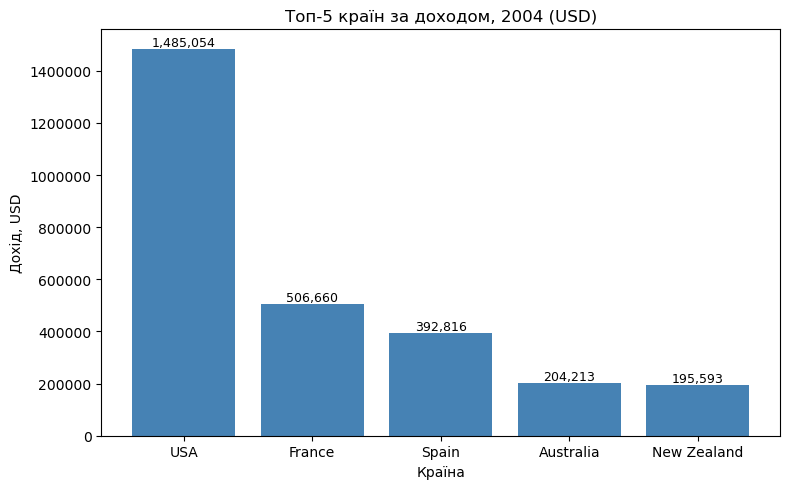

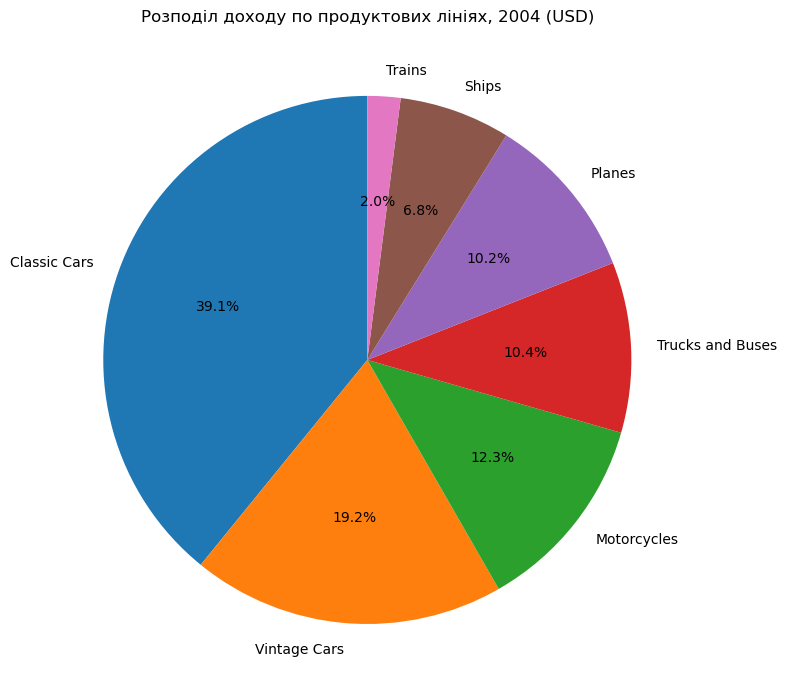

✅ Графіки збережено: top5_countries_revenue.png, product_lines_revenue_pie.png


In [17]:
# pip install openpyxl   # якщо ще не встановлено
import matplotlib.pyplot as plt

print("LOAD: зберігаємо результати...")

# 3.1 Excel з трьома вкладками
excel_path = "classicmodels_report_2004.xlsx"
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    df_summary.to_excel(writer, sheet_name="Summary", index=False)
    df_top_countries.to_excel(writer, sheet_name="Top_Countries", index=False)
    df_product_lines.to_excel(writer, sheet_name="Product_Lines", index=False)

    # ширина колонок
    for ws in writer.sheets.values():
        for col in ws.columns:
            width = max(len(str(c.value)) if c.value is not None else 0 for c in col)
            ws.column_dimensions[col[0].column_letter].width = width + 3
print(f"✅ Excel збережено: {excel_path}")

# 3.2 Стовпчикова діаграма: топ-5 країн за доходом
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(df_top_countries["country"], df_top_countries["total_revenue"], color="steelblue")
ax.set_title("Топ-5 країн за доходом, 2004 (USD)")
ax.set_xlabel("Країна")
ax.set_ylabel("Дохід, USD")
ax.ticklabel_format(style="plain", axis="y")
for i, v in enumerate(df_top_countries["total_revenue"]):
    ax.text(i, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig("top5_countries_revenue.png", dpi=150)
plt.show()

# Pie chart: розподіл доходу по продуктових лініях
fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(df_product_lines["total_revenue"],
       labels=df_product_lines["productLine"],
       autopct="%1.1f%%", startangle=90)
ax.set_title("Розподіл доходу по продуктових лініях, 2004 (USD)")
plt.tight_layout()
plt.savefig("product_lines_revenue_pie.png", dpi=150)
plt.show()

print("✅ Графіки збережено: top5_countries_revenue.png, product_lines_revenue_pie.png")